# HD 137010 b — Phase 3: eccentric orbits

The paper assumes a **circular orbit** ($e=0$). This notebook asks what happens to the inferred period, orbit and
habitable-zone (HZ) membership when that assumption is replaced by an explicit **prior on the eccentricity**.

**Why eccentricity matters for a single transit.** The light curve measures how fast the planet crosses the
star (the chord speed $v$). For a circular orbit that speed fixes the orbit size and hence the period via
Kepler's law. On an eccentric orbit the planet moves faster near its closest approach (periastron) and slower
far away, so the same speed is compatible with many periods:
$$
P \;=\; \frac{G\rho_\*}{3\pi v^3}\;g^3,\qquad g=\frac{1+e\sin\omega}{\sqrt{1-e^2}},
$$
where $\omega$ says *where* on the orbit the transit happens. In addition, eccentric planets near periastron are
**more likely to transit** (they are closer to the star), by the factor $(1+e\sin\omega)/(1-e^2)$; this
selection effect has to be part of every prior because we only consider planets that *were* seen to transit.

**Models** (all with $\omega\sim U(0,2\pi)$ and the transit-probability factor; a planet may not come closer
than $2R_\*$ to the star, roughly the Roche limit):

| | eccentricity prior | motivation |
|---|---|---|
| M0 | $e=0$ | the paper's assumption |
| M3 | Rayleigh($\sigma=0.049$) | small planets in multi-planet systems (Van Eylen et al. 2019) |
| M4 | Rayleigh with mean $e=0.15$ | the upper bound on the mean $e$ of temperate Earth-sized planets cited by the paper (Kipping et al. 2025) |
| M2 | Beta(0.867, 3.03) | radial-velocity planets (Kipping 2013); mostly giants |
| M1 | uniform on $[0,1)$ | "no idea" |

The period prior is the paper's ($\alpha=-1$, $p(P)\propto P^{-8/3}$, see Phase 2) unless stated otherwise.

**Method.** Phase 2 showed that fitting the light-curve *shape* (chord speed $v$, $b$, $k$, limb darkening)
once, and turning it into physical parameters afterwards, is both more reliable and far cheaper than refitting.
For each shape sample we draw $\rho_\*$, $e$, $\omega$ from their priors, compute $P$, and attach an
**importance weight** equal to the prior density of that $P$ times the transit factor
([`transit.shape_to_physical`](transit.py)). New here: on an eccentric orbit the planet–star distance changes
slightly during the 10-h transit, so the shape model is no longer exact; the weights are therefore multiplied by
$L_{\rm exact}/L_{\rm shape}$, the ratio of the full eccentric `batman` likelihood to the shape likelihood, which
makes the reweighting exact. Three models are re-fitted directly with nested sampling (`dynesty`) as an
independent check (Sec. 6).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy import stats
import transit as tr

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
t, f, P_MIN = tr.load_data()
REF = "loguniform_kipping"                     # paper's period prior, alpha = -1
ALPHAS = {"kipping": r"$\alpha=0$", "uniform_a_kipping": r"$\alpha=-2/3$", "loguniform_kipping": r"$\alpha=-1$ (paper)"}
MODELS = {"M0": "circular", "M3": "rayleigh_vaneylen19", "M4": "rayleigh_mean015",
          "M2": "beta_kipping13", "M1": "uniform"}
LABEL = {"M0": "M0: e = 0", "M3": "M3: Rayleigh 0.049", "M4": "M4: mean e = 0.15",
         "M2": "M2: Beta", "M1": "M1: uniform"}

sh = np.load("results/shape.npz")
ch = sh["chain"][sh["chain"].shape[0] // 2:]           # drop burn-in half
post = ch.reshape(-1, ch.shape[-1])[::20]
N_DRAWS = 20
n_indep = ch.shape[0] * ch.shape[1] * int(sh["thin"]) / sh["tau_history"][-1, 1:].max()
print(f"{len(post)} shape samples x {N_DRAWS} prior draws; ≈{n_indep:.0f} independent shape samples")

def wquantile(x, w, q):
    i = np.argsort(x)
    c = np.cumsum(w[i])
    return np.interp(q, c / c[-1], x[i])

def summ(x, w, fmt="{:.0f}"):
    lo, med, hi = wquantile(x, w, [0.15865, 0.5, 0.84135])
    return f"{fmt.format(med)} -{fmt.format(med - lo)} +{fmt.format(hi - med)}"

def pareto_khat(w):
    # PSIS diagnostic (Vehtari et al. 2015): GPD shape of the largest weights; k < 0.7 is reliable
    w = np.sort(w)[::-1]
    m = int(min(0.2 * len(w), 3 * np.sqrt(len(w))))
    return stats.genpareto.fit(w[:m] - w[m], floc=0)[0]

12500 shape samples x 20 prior draws; ≈5831 independent shape samples


/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/.venv/lib/python3.13/site-packages/batman/tests.py:107: SyntaxWarning: invalid escape sequence '\ '
  )   \     /   (
/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/.venv/lib/python3.13/site-packages/batman/tests.py:119: SyntaxWarning: invalid escape sequence '\/'
  /_ \/ |__


## 1. Reweighting

One expensive pass per eccentricity prior (exact likelihood for every draw, ~1 min each; cached in `results/`).
The period prior only changes the weight by a power of $P$, so the other $\alpha$ follow by a further cheap
reweighting. The evidence $Z$ (how well a model predicted the data) comes for free: it only needs the
normalisation of the prior (see the docstring of `shape_to_physical`).

In [2]:
def reweighted(e_prior):
    fn = Path(f"results/reweighted_{e_prior}.npz")
    if not fn.exists():
        th, e, om, w, lnz = tr.shape_to_physical(post, REF, e_prior, p_min=P_MIN, n_draws=N_DRAWS, rng=0,
                                                 return_lnz=True, data=None if e_prior == "circular" else (t, f))
        k = w > 0
        np.savez_compressed(fn, theta=th[k], e=e[k], om=om[k], w=w[k], lnz=lnz)
    r = np.load(fn)
    return {k: r[k] for k in r.files}

lnC = {(a, e): tr.log_prior_norm(a, e, P_MIN, tr.P_MAX, rng=1) for a in ALPHAS for e in MODELS.values()}
for a in ALPHAS:   # sanity check: for e = 0, C is analytic
    x = tr.PERIOD_PRIORS[a]
    print(f"{a:20s} ln C (MC) = {lnC[a, 'circular']:.4f}, analytic = {np.log((tr.P_MAX**x - P_MIN**x) / x):.4f}")

R = {}
for m, e_prior in MODELS.items():
    r = reweighted(e_prior)
    for a in ALPHAS:
        dx = tr.PERIOD_PRIORS[a] - tr.PERIOD_PRIORS[REF]
        lw = np.log(r["w"]) + dx * r["theta"][:, 1]
        mx = lw.max()
        w = np.exp(lw - mx)
        lnz = r["lnz"] + mx + np.log(w.sum()) - lnC[a, e_prior] + lnC[REF, e_prior] if a != REF else r["lnz"]
        R[m, a] = dict(theta=r["theta"], e=r["e"], om=r["om"], w=w / w.sum(), lnz=float(lnz),
                       d=tr.derived(r["theta"], rng=2, e=r["e"]))

kipping              ln C (MC) = -2.4759, analytic = -2.4759
uniform_a_kipping    ln C (MC) = -5.8477, analytic = -5.8477
loguniform_kipping   ln C (MC) = -7.4513, analytic = -7.4513


**Check against Phase 2.** For circular orbits the evidence ratio between $\alpha=0$ and $\alpha=-1$ from
reweighting can be compared with the two direct dynesty runs of Phase 2.

In [3]:
dz = {a: float(np.load(f"results/dynesty_{a}.npz")["logz"]) for a in ["kipping", "loguniform_kipping"]}
dze = {a: float(np.load(f"results/dynesty_{a}.npz")["logzerr"]) for a in dz}
print(f"ln B(alpha=0 vs -1), e=0:  reweighting {R['M0', 'kipping']['lnz'] - R['M0', REF]['lnz']:.2f}   "
      f"dynesty {dz['kipping'] - dz[REF]:.2f} ± {np.hypot(*dze.values()):.2f}")

ln B(alpha=0 vs -1), e=0:  reweighting 1.06   dynesty 0.80 ± 0.22


## 2. What do the data say about $e$?

Left of each panel: the prior on $e$ *for planets that transit* (prior × transit factor). Filled: the posterior.
A single transit carries little eccentricity information on its own: it constrains only the combination
$g^3/\rho_\*\cdot v^{-3}$, and for any $e$ there is an $\omega$ and a $P$ that fit. The information gain
(Kullback–Leibler divergence from the transit-conditioned prior to the posterior) quantifies this.

,prior|transit: e median,posterior: e median,posterior: e 95%,KL [bits]
model,,,,
M3: Rayleigh 0.049,0.058,0.058,0.121,0.000
M4: mean e = 0.15,0.143,0.149,0.309,0.004
M2: Beta,0.204,0.233,0.629,0.035
M1: uniform,0.836,0.515,0.923,0.575


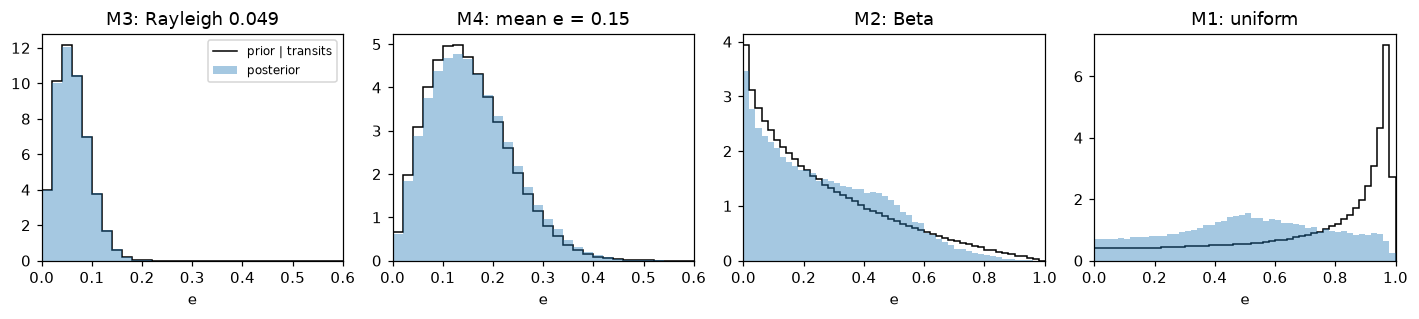

In [4]:
rng = np.random.default_rng(5)
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=False)
bins = np.linspace(0, 1, 51)
rows = []
for ax, m in zip(axes, ["M3", "M4", "M2", "M1"]):
    # full prior (period prior, rho*, transit factor, periastron cut), before seeing the light curve
    n = 2_000_000
    e0, om0 = tr.draw_e_w(MODELS[m], n, rng)
    lnP0 = rng.uniform(np.log(P_MIN), np.log(tr.P_MAX), n)
    lw0 = tr.log_orbit_weight(np.exp(lnP0), e0, om0, rng.normal(*tr.LOG_RHO_PRIOR, n), REF, P_MIN, tr.P_MAX)
    pw = np.exp(lw0 - lw0.max())
    hp, _ = np.histogram(e0, bins, weights=pw, density=True)
    r = R[m, REF]
    hq, _ = np.histogram(r["e"], bins, weights=r["w"], density=True)
    ax.stairs(hp, bins, color="k", label="prior | transits")
    ax.stairs(hq, bins, fill=True, alpha=0.4, label="posterior")
    ax.set(title=LABEL[m], xlabel="e", xlim=(0, 1 if m in ("M1", "M2") else 0.6))
    ok = (hq > 0) & (hp > 0)
    kl = np.sum(hq[ok] * np.log2(hq[ok] / hp[ok])) * np.diff(bins)[0]
    rows.append({"model": LABEL[m], "prior|transit: e median": wquantile(e0, pw, 0.5),
                 "posterior: e median": wquantile(r["e"], r["w"], 0.5),
                 "posterior: e 95%": wquantile(r["e"], r["w"], 0.95), "KL [bits]": kl})
axes[0].legend(fontsize=8)
fig.tight_layout()
display(pd.DataFrame(rows).set_index("model").round(3))

## 3. Period, orbit and habitable zone under each eccentricity prior ($\alpha=-1$)

HZ limits as quoted by the paper (Kopparapu et al. 2013 for this star): conservative $0.30$–$1.00\,I_\oplus$,
optimistic $0.27$–$1.60\,I_\oplus$. For an eccentric orbit we use the orbit-averaged insolation
$\langle I\rangle = L/(a^2\sqrt{1-e^2})$.

In [5]:
def hz(I, w, lim):
    return np.sum(w[(I > lim[0]) & (I < lim[1])])

def row(m, a):
    r = R[m, a]; d, w = r["d"], r["w"]
    return {"P [d]": summ(d["P"], w), "Pr(P<200 d)": np.sum(w[d["P"] < 200]),
            "a [AU]": summ(d["a_au"], w, "{:.2f}"), "I [I_earth]": summ(d["insolation"], w, "{:.2f}"),
            "Pr(HZ cons.)": hz(d["insolation"], w, tr.HZ_CONSERVATIVE),
            "Pr(HZ opt.)": hz(d["insolation"], w, tr.HZ_OPTIMISTIC),
            "Pr(hotter than HZ)": np.sum(w[d["insolation"] > tr.HZ_OPTIMISTIC[1]]),
            "ln B vs M0": r["lnz"] - R["M0", a]["lnz"],
            "ESS": 1 / np.sum(w**2), "k-hat": pareto_khat(w)}

tab = pd.DataFrame({LABEL[m]: row(m, REF) for m in MODELS}).T

# the authors' own samples (circular, alpha = -1) with the same HZ definition
au = pd.read_csv("posteriors.csv")
a_au = (tr.G * au.M.values * tr.MSUN * (au.P.values * tr.DAY) ** 2 / (4 * np.pi**2)) ** (1 / 3) / tr.AU
I_au = np.random.default_rng(3).normal(*tr.LUM, len(au)) / a_au**2
w_au = np.full(len(au), 1 / len(au))
tab.loc["authors' samples (e = 0)"] = {"P [d]": summ(au.P.values, w_au), "Pr(P<200 d)": np.mean(au.P < 200),
    "a [AU]": summ(a_au, w_au, "{:.2f}"), "I [I_earth]": summ(I_au, w_au, "{:.2f}"),
    "Pr(HZ cons.)": hz(I_au, w_au, tr.HZ_CONSERVATIVE), "Pr(HZ opt.)": hz(I_au, w_au, tr.HZ_OPTIMISTIC),
    "Pr(hotter than HZ)": np.mean(I_au > tr.HZ_OPTIMISTIC[1])}
display(tab.round(3))
print("paper text: P = 355 -59 +200 d, a = 0.88 -0.10 +0.32 AU, I = 0.29 -0.13 +0.11, Pr(HZ) = 40% / 51%")

,P [d],Pr(P<200 d),a [AU],I [I_earth],Pr(HZ cons.),Pr(HZ opt.),Pr(hotter than HZ),ln B vs M0,ESS,k-hat
M0: e = 0,356 -59 +171,0.000016,0.88 -0.10 +0.26,0.29 -0.12 +0.09,0.472974,0.588471,0.0,0.0,172791.970513,-0.051279
M3: Rayleigh 0.049,355 -79 +175,0.006113,0.88 -0.14 +0.27,0.30 -0.12 +0.13,0.487873,0.585969,0.0,0.012669,166094.049542,-0.020314
M4: mean e = 0.15,322 -115 +215,0.141178,0.83 -0.21 +0.34,0.34 -0.17 +0.29,0.541704,0.6361,0.006777,0.076122,134035.84518,0.101772
M2: Beta,275 -158 +216,0.344623,0.74 -0.32 +0.35,0.43 -0.24 +1.07,0.435522,0.584842,0.145403,0.124638,83002.964441,-0.070576
M1: uniform,157 -76 +242,0.599972,0.51 -0.18 +0.44,1.13 -0.84 +1.93,0.29516,0.457044,0.393603,-0.520181,42461.688978,0.446712
authors' samples (e = 0),355 -59 +190,0.0,0.88 -0.10 +0.29,0.29 -0.13 +0.09,0.47778,0.5894,0.0,NaN,NaN,NaN


paper text: P = 355 -59 +200 d, a = 0.88 -0.10 +0.32 AU, I = 0.29 -0.13 +0.11, Pr(HZ) = 40% / 51%


The **effective sample size** (ESS) of the weights shows how many equally weighted samples the reweighted set is
worth; $\hat k<0.7$ means the importance weights have a finite-variance tail and the estimates are reliable.
Because consecutive shape samples are correlated, the number of *independent* samples behind each estimate is
roughly (independent shape samples) × ESS / N; for the broadest prior (M1) this is still about a thousand.

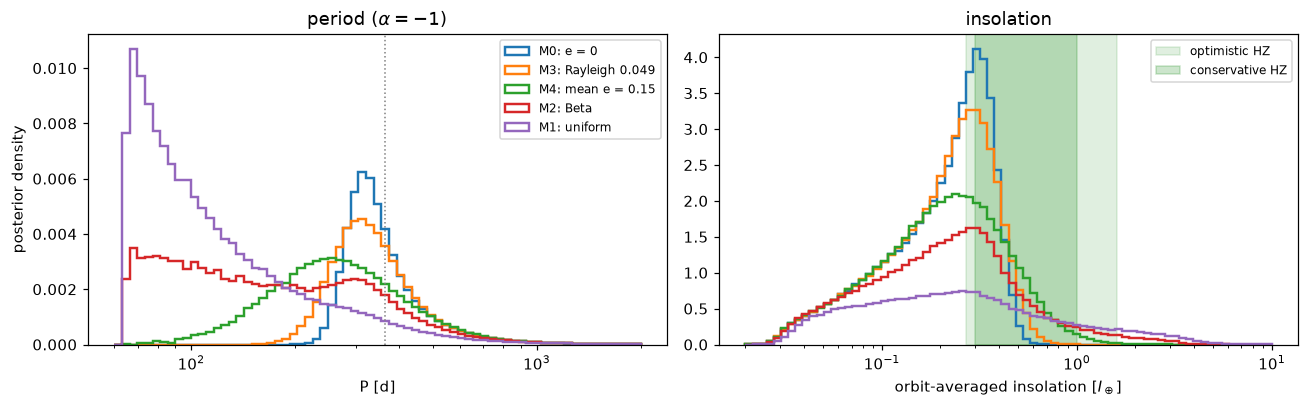

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for m in MODELS:
    r = R[m, REF]
    axes[0].hist(r["d"]["P"], bins=np.geomspace(60, 2000, 70), weights=r["w"], density=True,
                 histtype="step", lw=1.6, label=LABEL[m])
    axes[1].hist(r["d"]["insolation"], bins=np.geomspace(0.02, 10, 75), weights=r["w"], density=True,
                 histtype="step", lw=1.6)
axes[0].set(xscale="log", xlabel="P [d]", ylabel="posterior density", title=r"period ($\alpha=-1$)")
axes[0].axvline(365.25, color="gray", ls=":", lw=1)
axes[0].legend(fontsize=8)
axes[1].axvspan(*tr.HZ_OPTIMISTIC, color="g", alpha=0.12, label="optimistic HZ")
axes[1].axvspan(*tr.HZ_CONSERVATIVE, color="g", alpha=0.2, label="conservative HZ")
axes[1].set(xscale="log", xlabel=r"orbit-averaged insolation [$I_\oplus$]", title="insolation")
axes[1].legend(fontsize=8)
fig.tight_layout()

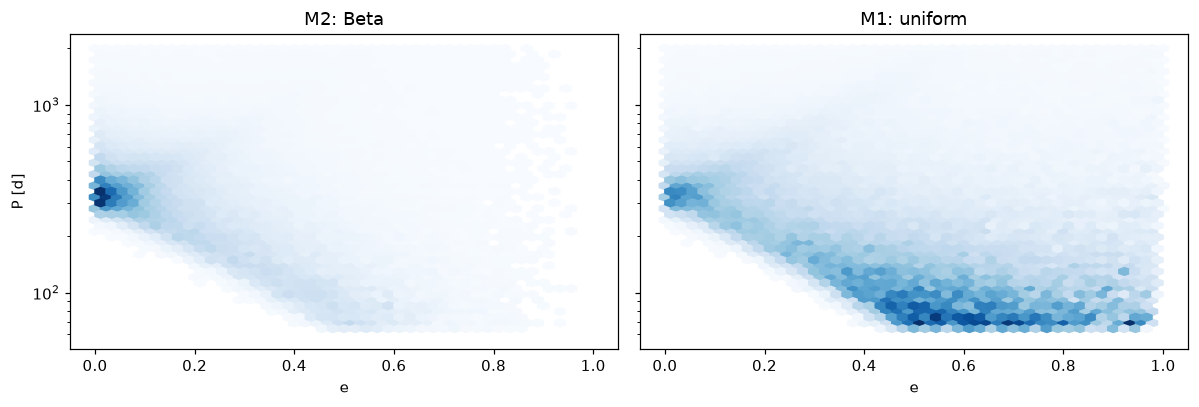

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, m in zip(axes, ["M2", "M1"]):
    r = R[m, REF]
    ax.hexbin(r["e"], r["d"]["P"], C=r["w"], reduce_C_function=np.sum, gridsize=45, yscale="log",
              cmap="Blues", mincnt=1, extent=(0, 1, np.log10(60), np.log10(2000)))
    ax.set(xlabel="e", title=LABEL[m])
axes[0].set_ylabel("P [d]")
fig.tight_layout()

## 4. The paper's argument for neglecting $e$

The paper argues that "for small orbital eccentricities ($\lesssim0.2$), the impact on the orbital period
uncertainty is not larger than the uncertainty arising from the impact parameter". Since
$\ln P = \ln P_{\rm circ}(v,\rho_\*) + 3\ln g$, the posterior spread of $\ln P$ splits into the part from the
circular-orbit period (driven by $b$ and $\rho_\*$) and the part from the eccentricity factor $g$:

In [8]:
rows = []
for m in MODELS:
    r = R[m, REF]; w = r["w"]
    lnP = r["theta"][:, 1]
    lng3 = 3 * np.log(tr.g_factor(r["e"], r["om"]))
    sd = lambda x: (wquantile(x, w, 0.84135) - wquantile(x, w, 0.15865)) / 2
    rows.append({"model": LABEL[m], "68% half-width ln P": sd(lnP), "  from P_circ (b, rho*)": sd(lnP - lng3),
                 "  from 3 ln g (e, w)": sd(lng3), "Pr(e > 0.2)": np.sum(w[r["e"] > 0.2])})
display(pd.DataFrame(rows).set_index("model").round(3))

,68% half-width ln P,"from P_circ (b, rho*)","from 3 ln g (e, w)",Pr(e > 0.2)
model,,,,
M0: e = 0,0.287,0.287,0.000,0.000
M3: Rayleigh 0.049,0.326,0.287,0.147,0.000
M4: mean e = 0.15,0.477,0.286,0.366,0.285
M2: Beta,0.718,0.306,0.646,0.555
M1: uniform,0.797,0.377,0.827,0.853


## 5. Sensitivity to the period prior

The same table for the three single-transit period priors of Phase 2. Shown: median period, the probability of a
"short" period $P<200$ d, and the probability of lying in the conservative HZ.

In [9]:
grid = {}
for a, al in ALPHAS.items():
    for m in MODELS:
        r = R[m, a]; d, w = r["d"], r["w"]
        grid[al, m] = {"P median [d]": wquantile(d["P"], w, 0.5), "Pr(P<200 d)": np.sum(w[d["P"] < 200]),
                       "Pr(HZ cons.)": hz(d["insolation"], w, tr.HZ_CONSERVATIVE),
                       "ln Z (rel. M0, alpha=-1)": r["lnz"] - R["M0", REF]["lnz"]}
g = pd.DataFrame(grid).T
for col in g.columns:
    print(col); display(g[col].unstack()[list(MODELS)].round(2 if "P median" not in col else 0))

P median [d]


,M0,M3,M4,M2,M1
$\alpha=-1$ (paper),356.0,355.0,322.0,275.0,157.0
$\alpha=-2/3$,365.0,368.0,348.0,313.0,205.0
$\alpha=0$,396.0,405.0,416.0,398.0,359.0


Pr(P<200 d)


,M0,M3,M4,M2,M1
$\alpha=-1$ (paper),0.0,0.01,0.14,0.34,0.60
$\alpha=-2/3$,0.0,0.00,0.11,0.26,0.49
$\alpha=0$,0.0,0.00,0.06,0.13,0.27


Pr(HZ cons.)


,M0,M3,M4,M2,M1
$\alpha=-1$ (paper),0.47,0.49,0.54,0.44,0.30
$\alpha=-2/3$,0.43,0.44,0.49,0.42,0.32
$\alpha=0$,0.35,0.35,0.37,0.34,0.31


ln Z (rel. M0, alpha=-1)


,M0,M3,M4,M2,M1
$\alpha=-1$ (paper),0.00,0.01,0.08,0.12,-0.52
$\alpha=-2/3$,0.39,0.40,0.42,0.40,-0.38
$\alpha=0$,1.06,1.06,1.04,0.93,-0.05


## 6. Independent checks

Three routes to the same posterior, for M0, M4, M2 and M1 (period prior $\alpha=-1$):

* **emcee shape + reweighting**, as above;
* **dynesty shape + reweighting**: nested sampling of the shape model ([`run_dynesty.py`](run_dynesty.py) `--shape`),
  then the identical reweighting. Tests the emcee shape chain, and gives the *absolute* evidence of the shape
  model, so that the reweighting evidences $\ln Z_{\rm shape}+\ln(Z_M/Z_{\rm shape})$ can be compared in absolute terms;
* **direct dynesty**: the full eccentric `batman` model in the physical parameters ($P,b,\rho_\*,e,\omega,\dots$;
  `--e-prior`), sharing nothing with the reweighting except the likelihood. Its evidence is normalised with
  the same prior constant $C$.

The last row block repeats the circular case with the authors' own chain ($10^8$ emcee steps) as a fourth reference.

/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/ian/transit.py:343: UserWarning: 2 draws (max e = 0.9798, weight 4.2e-05) kept the shape approximation
  warnings.warn(f"{len(failed)} draws (max e = {e[failed].max():.4f}, weight {frac:.1e}) "


/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/ian/transit.py:367: RuntimeWarning: invalid value encountered in arccos
  inc = np.arccos(b / aR)


P [d]  Pr(P<200 d)  \
model             method                                                    
M0: e = 0         emcee shape + reweighting     356 -59 +171        0.000   
                  dynesty shape + reweighting   351 -58 +162        0.000   
                  direct dynesty                347 -54 +150        0.000   
                  authors' emcee chain          355 -59 +190        0.000   
M4: mean e = 0.15 emcee shape + reweighting    322 -115 +215        0.141   
                  dynesty shape + reweighting  317 -114 +211        0.150   
                  direct dynesty               302 -111 +203        0.184   
M2: Beta          emcee shape + reweighting    275 -158 +216        0.345   
                  dynesty shape + reweighting  271 -156 +212        0.350   
                  direct dynesty               247 -131 +184        0.384   
M1: uniform       emcee shape + reweighting     157 -76 +242        0.600   
                  dynesty shape + reweighting   154 -73 +241        0.606   
                  direct dynesty                123 -46 +167        0.701   

                                               e median  Pr(b<0.3)  \
model             method                                             
M0: e = 0         emcee shape + reweighting       0.000      0.497   
                  dynesty shape + reweighting     0.000      0.517   
                  direct dynesty                  0.000      0.560   
                  authors' emcee chain            0.000      0.511   
M4: mean e = 0.15 emcee shape + reweighting       0.149      0.497   
                  dynesty shape + reweighting     0.149      0.517   
                  direct dynesty                  0.152      0.540   
M2: Beta          emcee shape + reweighting       0.233      0.472   
                  dynesty shape + reweighting     0.234      0.493   
                  direct dynesty                  0.232      0.526   
M1: uniform       emcee shape + reweighting       0.515      0.413   
                  dynesty shape + reweighting     0.515      0.427   
                  direct dynesty                  0.600      0.513   

                                               Pr(HZ cons.)      ln Z  \
model             method                                                
M0: e = 0         emcee shape + reweighting           0.473       NaN   
                  dynesty shape + reweighting         0.495  1224.610   
                  direct dynesty                      0.511  1224.680   
                  authors' emcee chain                0.478       NaN   
M4: mean e = 0.15 emcee shape + reweighting           0.542       NaN   
                  dynesty shape + reweighting         0.552  1224.687   
                  direct dynesty                      0.573  1224.322   
M2: Beta          emcee shape + reweighting           0.436       NaN   
                  dynesty shape + reweighting         0.440  1224.736   
                  direct dynesty                      0.487  1224.729   
M1: uniform       emcee shape + reweighting           0.295       NaN   
                  dynesty shape + reweighting         0.291  1224.096   
                  direct dynesty                      0.266  1224.083   

                                               ln Z err  
model             method                                 
M0: e = 0         emcee shape + reweighting         NaN  
                  dynesty shape + reweighting     0.157  
                  direct dynesty                  0.154  
                  authors' emcee chain              NaN  
M4: mean e = 0.15 emcee shape + reweighting         NaN  
                  dynesty shape + reweighting     0.157  
                  direct dynesty                  0.155  
M2: Beta          emcee shape + reweighting         NaN  
                  dynesty shape + reweighting     0.157  
                  direct dynesty                  0.153  
M1: uniform       emcee shape + reweighting         NaN 

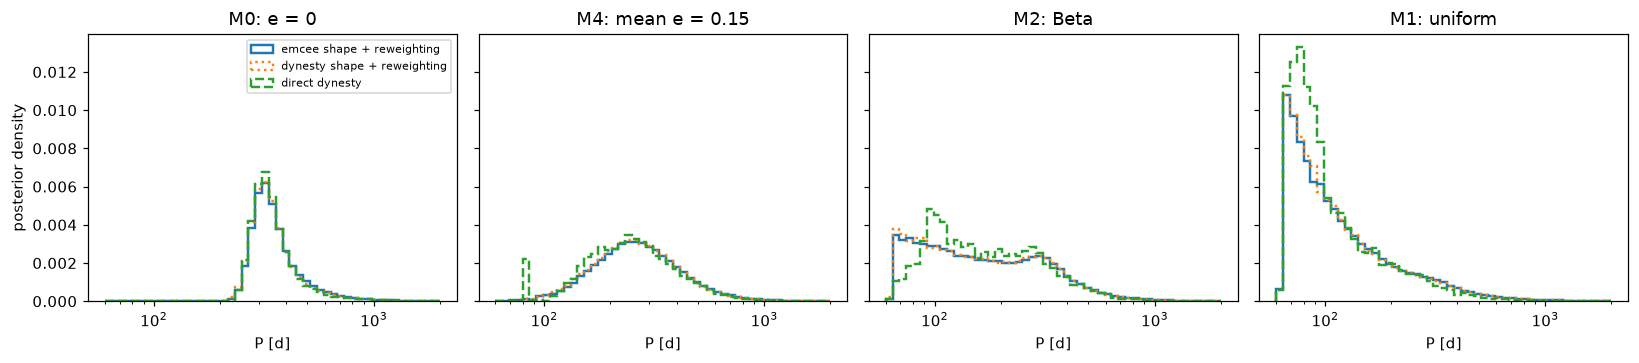

In [10]:
dsh = np.load("results/dynesty_shape.npz")
S = dsh["samples"]
S = S[np.random.default_rng(0).choice(len(S), len(post), replace=False)]
lnZ_shape = float(dsh["logz"])
x = tr.PERIOD_PRIORS[REF]
rows, hists = [], {}
for m in ["M0", "M4", "M2", "M1"]:
    ep = MODELS[m]
    dy = np.load(f"results/dynesty_{REF}" + ("" if ep == "circular" else f"_{ep}") + ".npz")
    s = dy["samples"]
    e_dy = np.zeros(len(s)) if ep == "circular" else s[:, 10]
    lnz_dy = float(dy["logz"]) + (0 if ep == "circular" else np.log((tr.P_MAX**x - P_MIN**x) / x) - lnC[REF, ep])
    th, e2, om2, w2, lnz2 = tr.shape_to_physical(S, REF, ep, p_min=P_MIN, n_draws=N_DRAWS, rng=0, return_lnz=True,
                                                 data=None if ep == "circular" else (t, f))
    r = R[m, REF]
    methods = [("emcee shape + reweighting", r["d"], r["w"], r["e"], r["theta"][:, 2], np.nan, np.nan),
               ("dynesty shape + reweighting", tr.derived(th, rng=2, e=e2), w2, e2, th[:, 2], lnZ_shape + lnz2,
                float(dsh["logzerr"])),
               ("direct dynesty", tr.derived(s[:, :10], rng=2, e=e_dy), np.full(len(s), 1 / len(s)), e_dy, s[:, 2],
                lnz_dy, float(dy["logzerr"]))]
    if m == "M0":
        methods.append(("authors' emcee chain", {"P": au.P.values, "insolation": I_au}, w_au, np.zeros(len(au)),
                        au.b.values, np.nan, np.nan))
    for lab, d, w, e, b, lnz, err in methods:
        rows.append({"model": LABEL[m], "method": lab, "P [d]": summ(d["P"], w),
                     "Pr(P<200 d)": np.sum(w[d["P"] < 200]), "e median": wquantile(e, w, 0.5),
                     "Pr(b<0.3)": np.sum(w[b < 0.3]), "Pr(HZ cons.)": hz(d["insolation"], w, tr.HZ_CONSERVATIVE),
                     "ln Z": lnz, "ln Z err": err})
        hists[m, lab] = (d["P"], w)
display(pd.DataFrame(rows).set_index(["model", "method"]).round(3))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, m in zip(axes, ["M0", "M4", "M2", "M1"]):
    for lab, ls in [("emcee shape + reweighting", "-"), ("dynesty shape + reweighting", ":"), ("direct dynesty", "--")]:
        P, w = hists[m, lab]
        ax.hist(P, bins=np.geomspace(60, 2000, 50), weights=w, density=True, histtype="step", lw=1.6, ls=ls, label=lab)
    ax.set(xscale="log", xlabel="P [d]", title=LABEL[m])
axes[0].set_ylabel("posterior density"); axes[0].legend(fontsize=7)
fig.tight_layout()

The two shape-space samplers agree with each other, and the **absolute evidences** from reweighting agree with the
direct nested-sampling evidences to within their errors (M4 is the exception at ≈2σ), which validates the whole
reweighting chain including the prior normalisation. The direct dynesty *posteriors* are shifted to lower impact
parameter ($\Pr(b<0.3)$ higher by ≈0.05), already in the circular case where both shape samplers and the authors'
chain agree with each other. With an eccentricity prior this low-$b$ (faster chord) excess becomes an excess of short
periods. We attribute it to the slice-sampling proposals of nested sampling in 12 correlated dimensions (the evidence
is less sensitive to this than the posterior shape) and adopt the reweighted results; the spread between the
methods is a fair measure of the remaining systematic uncertainty (≈0.05–0.1 in $\Pr(P<200\,{\rm d})$).

## 7. Summary

**Results (paper's period prior, $\alpha=-1$; Sec. 3):**

| model | $P$ [d] | $\Pr(P<200\,{\rm d})$ | $\langle I\rangle$ [$I_\oplus$] | Pr(HZ cons. / opt.) | Pr(hotter than HZ) |
|---|---|---|---|---|---|
| M0 $e=0$ | 356 −59 +171 | 0 | 0.29 −0.12 +0.09 | 47% / 59% | 0 |
| M3 Rayleigh 0.049 | 355 −79 +175 | 1% | 0.30 −0.12 +0.13 | 49% / 59% | 0 |
| M4 mean $e=0.15$ | 322 −115 +215 | 14% | 0.34 −0.17 +0.29 | 54% / 64% | 1% |
| M2 Beta | 275 −158 +216 | 34% | 0.43 −0.24 +1.07 | 44% / 58% | 15% |
| M1 uniform | 157 −76 +242 | 60% | 1.1 −0.8 +1.9 | 30% / 46% | 39% |

1. **The light curve says (almost) nothing about $e$.** For M3, M4 and M2 the eccentricity posterior equals the
   transit-conditioned prior (information gain ≤ 0.04 bits; Sec. 2). Whatever is assumed about $e$ comes straight
   back out, and with it the period.
2. **Under the paper's own justification the result is not robust.** The paper cites a mean $e\lesssim0.15$ for
   comparable planets and argues that $e\lesssim0.2$ adds less period uncertainty than $b$. That holds for the
   nearly-circular M3 (eccentricity part of the spread in $\ln P$: 0.15 vs 0.29 from $b,\rho_\*$), but for M4, the
   prior matching the cited bound, the eccentricity part (0.37) already exceeds the $b$ part (Sec. 4); the
   period becomes $322^{+215}_{-115}$ d with a 14% chance of $P<200$ d.
3. **The HZ conclusion is fairly stable, its direction is not.** The probability of lying in the conservative HZ
   stays at 44–54% for every prior except uniform $e$ (30%). But with $e=0$ every non-HZ solution is *too cold*,
   whereas with broader priors a growing fraction is *too hot* (15% for Beta, 39% for uniform): "near the outer
   edge of the HZ" is a consequence of $e=0$.
4. **The data cannot pick the prior.** All Bayes factors between the eccentricity priors satisfy $|\ln B|\le0.6$
   (Sec. 3, 5): the choice must be made on physical/population grounds (Phase 5 will look at this more formally).
5. **Period-prior interplay** (Sec. 5): with $\alpha=0$ (more weight on long periods) the eccentric short-period
   solutions are suppressed ($\Pr(P<200\,{\rm d})$ = 13% for Beta, 27% for uniform), so the two prior choices
   compound. For M2/M1 the posterior piles up at the lower cut $P_{\min}=64$ d (no second transit in K2), i.e. it is
   bounded by the observing window rather than by the transit.
6. **HZ numbers in the paper.** With the paper's own HZ limits and the authors' own posterior samples we obtain
   48% / 59% (conservative / optimistic), not the 40% / 51% quoted in the text; our circular fit agrees with the
   former.

**Validation** (Sec. 1, 6): exact eccentric likelihood in the weights; Pareto $\hat k<0.5$ and ESS ≥ 4×10⁴ for all
models; two different samplers in shape space agree; reweighting evidences agree with direct nested sampling in
absolute terms. Direct nested sampling in the physical parameters prefers slightly lower $b$ (also for $e=0$,
where the authors' chain sides with the shape samplers), which turns into ≈0.05–0.1 more mass at $P<200$ d;
this is the main remaining systematic.

**Not yet included:** correlated (red) noise in the light curve (Phase 1 PPC), the exact Kipping et al. (2025)
eccentricity posterior (M4 is the most permissive distribution consistent with their quoted bound), and a formal
model comparison / predictive checks of the eccentric models (Phase 5).